# 🚀 Entraînement du modèle Visual Question Answering avec GNN

Ce notebook configure et entraîne un modele de Visual Question Answering avec GNN multimodal.

In [200]:
# Imports nécessaires
from options.train_options import TrainOptions

# ⚙️ CONFIGURATION GLOBALE
# Modifiez ces variables pour changer la taille du dataset
TOTAL_QUESTIONS = 2000  # Nombre total de questions (train + val)
TRAIN_SPLIT = 0.8      # Proportion d'entraînement (0.8 = 80%)
EPOCH = 20
# 🎯 TOGGLE PRINCIPAL : Mode de tâche
# ========================================
# 0 = MODE EXECUTOR (original) : Génère un programme, l'executor l'exécute pour obtenir la réponse
# 1 = MODE CLASSIFICATION (nouveau) : Prédit directement la réponse via MLP, sans programme ni executor
# ========================================
CLASSIFICATION_MODE = 1  # 🔥 CHANGEZ ICI POUR SWITCHER DE MODE!

opt = TrainOptions().parse()

# 🔥 Options pour le choix des GNN
opt.gembd_vec_dim = 96
opt.gnn = 'gin'
opt.two_stream_gnn = 0


# Calcul automatique des tailles
TRAIN_SIZE = int(TOTAL_QUESTIONS * TRAIN_SPLIT)
VAL_SIZE = TOTAL_QUESTIONS - TRAIN_SIZE

print(f"⚙️ CONFIGURATION:")
print(f"   - Total questions: {TOTAL_QUESTIONS}")
print(f"   - Train size: {TRAIN_SIZE}")
print(f"   - Val size: {VAL_SIZE}")
print(f"   - Dossier de sortie: clevr_preprocessed_{TOTAL_QUESTIONS}")
print()
if CLASSIFICATION_MODE:
    print("🎯 MODE: CLASSIFICATION (End-to-End VQA)")
    print("   → Prédiction directe de la réponse via MLP")
    print("   → Pas de génération de programme")
    print("   → Pas d'executor symbolique")
else:
    print("🎯 MODE: EXECUTOR (Programme + Exécution)")
    print("   → Génération de programme séquence")
    print("   → Exécution par l'executor symbolique")
    print("   → Réponse via lookup dans la scène")

DEBUG base_options.py: 118: ----------------------------------------------------------------------------------------------------
DEBUG base_options.py: 119: Run identifier: reason.run_train-pretrain-GIN-singlestream-clevr_train_questions-20000num_iters.Nonetr_samples.10000val_samples.64bsz-PC_guillaume-20260106-032943
DEBUG base_options.py: 120: ----------------------------------------------------------------------------------------------------


| FORCED CPU MODE - GPU disabled via FORCE_CPU_MODE environment variable
| options
run_dir: _scratch/test_run
dataset: clevr
shuffle: 1
num_workers: 1
manual_seed: None
gpu_ids: []
visualize: 0
clevr_train_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_train_scenes.json
clevr_val_scene_path: ../data/raw/CLEVR_v1.0/scenes/CLEVR_val_scenes.json
clevr_train_question_path: ../data/reason/clevr_h5/clevr_train_questions.h5
clevr_val_question_path: ../data/reason/clevr_mgn_h5/clevr_val_questions.h5
clevr_test_question_path: ../data/reason/clevr_mgn_h5/clevr_test_questions.h5
clevr_vocab_path: ../data/reason/clevr_h5/clevr_vocab.json
visualize_training_wandb: 0
tags: 
is_directed_graph: 1
wandb_proj_name: mgn_vector
clevr_train_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/train_scenes_parsed.json
clevr_val_parsed_scene_path: ../../data/CLEVR_v1.0/scenes_parsed/val_scenes_parsed.json
clevr_train_raw_question_path: ../../data/CLEVR_v1.0/questions/CLEVR_train_questions.json
clevr_val_r

In [201]:
# 📝 Configuration pour 100 epochs AVEC GNN ACTIVÉ
import sys
import os


# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

# Forcer le mode CPU (changez si vous avez un GPU)
os.environ['FORCE_CPU_MODE'] = 'true'
os.environ['CUDA_VISIBLE_DEVICES'] = ''

# 🎯 MODE CLASSIFICATION (toggle depuis la cellule de config)
opt.classification_mode = CLASSIFICATION_MODE
opt.classifier_hidden_dim = 256
opt.classifier_dropout = 0.1

# ⚠️ UTILISER LE VOCABULAIRE DU DOSSIER DYNAMIQUE - chemins relatifs
opt.clevr_vocab_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_vocab.json')
opt.clevr_train_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_train_questions.h5')
opt.clevr_val_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'clevr_val_questions.h5')

# Chemins vers les scènes pour l'executor et la génération dynamique de graphes - chemins relatifs
opt.clevr_train_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_train_scenes.json')
opt.clevr_val_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_val_scenes.json')
opt.clevr_train_parsed_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_train_scenes.json')
opt.clevr_val_parsed_scene_path = os.path.join(os.getcwd(), 'data', 'CLEVR_v1.0', 'scenes', 'CLEVR_val_scenes.json')

# Chemins vers les questions brutes pour génération dynamique - chemins relatifs
opt.clevr_train_raw_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'temp', f'train_questions_{TRAIN_SIZE}.json')
opt.clevr_val_raw_question_path = os.path.join(os.getcwd(), OUTPUT_DIR, 'temp', f'val_questions_{VAL_SIZE}.json')

opt.max_train_samples = TRAIN_SIZE
opt.max_val_samples = VAL_SIZE
opt.batch_size = 16

# 🚀 ENTRAÎNEMENT: 100 epochs
# Calcul dynamique des itérations
batches_per_epoch = max(1, TRAIN_SIZE // opt.batch_size)
opt.num_iters = batches_per_epoch * EPOCH  # 100 epochs
opt.checkpoint_every = batches_per_epoch * 5  # Validation toutes les 5 epochs
opt.display_every = batches_per_epoch  # Afficher à chaque epoch

# ✅ ACTIVER TensorBoard pour la visualisation
opt.visualize_training = 1
opt.visualize_training_wandb = 0

opt.num_workers = 0  # Important pour Windows
opt.is_train = True

## 1. Imports

In [202]:
import os, sys

# 🛠️ Configuration des paths Python
# Utiliser le chemin du notebook pour trouver le workspace de manière portable
workspace = os.path.dirname(os.path.abspath(__file__)) if '__file__' in globals() else os.getcwd()
os.chdir(workspace)
sys.path.insert(0, workspace)

# FORCER le rechargement de TOUS les modules du projet
import importlib
# Ajouter 'trainer' à la liste
modules_to_reload = [m for m in list(sys.modules.keys()) if m.startswith(('datasets', 'utils', 'models', 'options', 'executors', 'trainer'))]
for mod_name in modules_to_reload:
    del sys.modules[mod_name]
print(f"♻️ {len(modules_to_reload)} modules supprimés du cache")

print(f"📁 Working dir: {os.getcwd()}")

# 📦 Imports des modules nécessaires
try:
    from options.train_options import TrainOptions
    from datasets import ClevrData
    from executors import get_executor
    print("✅ Imports de base réussis!")
    print("   - TrainOptions disponible")
    print("   - ClevrData disponible")
    print("   - Executors disponible")
except ImportError as e:
    print(f"❌ Erreur d'import: {e}")
    raise

♻️ 25 modules supprimés du cache
📁 Working dir: d:\visual-question-answering-gnn
PROJECT_ROOT=d:\visual-question-answering-gnn
CLEVR_PARSER_PATH=d:\visual-question-answering-gnn\clevr-parser


DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer


✅ Imports de base réussis!
   - TrainOptions disponible
   - ClevrData disponible
   - Executors disponible


## 2. Preprocessing

In [203]:
# 🎯 Preprocessing des échantillons
import subprocess, sys, os, json, h5py

OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'
os.makedirs(f'{OUTPUT_DIR}/temp', exist_ok=True)

# Vérifier si preprocessing déjà fait
train_h5 = f'{OUTPUT_DIR}/clevr_train_questions.h5'
val_h5 = f'{OUTPUT_DIR}/clevr_val_questions.h5'
vocab_file = f'{OUTPUT_DIR}/clevr_vocab.json'

if os.path.exists(train_h5) and os.path.exists(val_h5) and os.path.exists(vocab_file):
    with h5py.File(train_h5, 'r') as f:
        train_count = len(f['questions'])
    with h5py.File(val_h5, 'r') as f:
        val_count = len(f['questions'])
    print(f"✅ Preprocessing déjà effectué!")
    print(f"   - Train: {train_count} questions dans {train_h5}")
    print(f"   - Val: {val_count} questions dans {val_h5}")
    print(f"   - Vocab: {vocab_file}")
else:
    print(f"📊 Preprocessing: {TRAIN_SIZE} train + {VAL_SIZE} val")
    
    # Créer sous-ensembles de questions
    for split, size, src in [('train', TRAIN_SIZE, 'CLEVR_train_questions.json'), 
                              ('val', VAL_SIZE, 'CLEVR_val_questions.json')]:
        json_out = f'{OUTPUT_DIR}/temp/{split}_questions_{size}.json'
        if not os.path.exists(json_out):
            with open(f'data/CLEVR_v1.0/questions/{src}', 'r') as f:
                data = json.load(f)
                data['questions'] = data['questions'][:size]
            with open(json_out, 'w') as f:
                json.dump(data, f)
        print(f"✅ {split}: {size} questions")
    
    # Vocabulaire unifié
    if not os.path.exists(vocab_file):
        with open(f'{OUTPUT_DIR}/temp/train_questions_{TRAIN_SIZE}.json', 'r') as f:
            train_q = json.load(f)['questions']
        with open(f'{OUTPUT_DIR}/temp/val_questions_{VAL_SIZE}.json', 'r') as f:
            val_q = json.load(f)['questions']
        with open(f'{OUTPUT_DIR}/temp/all_questions_{TOTAL_QUESTIONS}.json', 'w') as f:
            json.dump({'questions': train_q + val_q}, f)
        
        subprocess.run([sys.executable, 'tools/preprocess_questions.py', '--mode', 'prefix',
                        '--input_questions_json', f'{OUTPUT_DIR}/temp/all_questions_{TOTAL_QUESTIONS}.json',
                        '--output_h5_file', f'{OUTPUT_DIR}/temp/dummy.h5',
                        '--output_vocab_json', vocab_file], check=True, capture_output=True)
        print(f"✅ Vocabulaire créé")
    
    # Preprocessing train/val
    for split, size in [('train', TRAIN_SIZE), ('val', VAL_SIZE)]:
        h5_file = f'{OUTPUT_DIR}/clevr_{split}_questions.h5'
        if not os.path.exists(h5_file):
            subprocess.run([sys.executable, 'tools/preprocess_questions.py', '--mode', 'prefix',
                            '--input_questions_json', f'{OUTPUT_DIR}/temp/{split}_questions_{size}.json',
                            '--output_h5_file', h5_file,
                            '--input_vocab_json', vocab_file], check=True, capture_output=True)
        with h5py.File(h5_file, 'r') as f:
            print(f"✅ {split}: {len(f['questions'])} questions dans H5")
    
    print(f"✅ Preprocessing terminé!")


✅ Preprocessing déjà effectué!
   - Train: 1600 questions dans clevr_preprocessed_2000/clevr_train_questions.h5
   - Val: 400 questions dans clevr_preprocessed_2000/clevr_val_questions.h5
   - Vocab: clevr_preprocessed_2000/clevr_vocab.json


In [ ]:
# 🚀 Précalcul des graphes
import sys, os, argparse, logging

OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'

train_graph_file = f'{OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt'
val_graph_file = f'{OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt'

if os.path.exists(train_graph_file) and os.path.exists(val_graph_file):
    train_size = os.path.getsize(train_graph_file) / (1024 * 1024)
    val_size = os.path.getsize(val_graph_file) / (1024 * 1024)
    print(f"✅ Graphes déjà précalculés ({train_size:.1f} MB train, {val_size:.1f} MB val)\n")
else:
    print(f"⚠️  Génération des graphes ({TRAIN_SIZE} train, {VAL_SIZE} val)...")
    
    # Rechargement et configuration
    if 'tools.sample_questions_mgn' in sys.modules:
        del sys.modules['tools.sample_questions_mgn']
    
    import tqdm.std, tqdm.notebook
    tqdm.std.tqdm = tqdm.notebook.tqdm
    
    from tools.sample_questions_mgn import main as sample_main, logger
    logger.setLevel(logging.WARNING)
    
    # Configuration commune
    base_args = {
        'random_sample': 1,
        'output_dir': OUTPUT_DIR,
        'output_index': None,
        'input_vocab_json': f'{OUTPUT_DIR}/clevr_vocab.json',
        'expand_vocab': 0,
        'is_debug': False,
        'is_directed_graph': 1,
        'parser_lm': 'en_core_web_sm',
        'model': ''
    }
    
    # Train
    if not os.path.exists(train_graph_file):
        print(f"📊 Train ({TRAIN_SIZE} questions)...")
        train_args = argparse.Namespace(
            **base_args,
            max_sample=TRAIN_SIZE,
            n_questions_per_family=2,
            input_question_h5=f'{OUTPUT_DIR}/clevr_train_questions.h5',
            input_questions_json=f'{OUTPUT_DIR}/temp/train_questions_{TRAIN_SIZE}.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_train_scenes.json'
        )
        try:
            sample_main(train_args)
            print("✅ Train terminé")
        except Exception as e:
            print(f"❌ Erreur train: {e}")
            raise
    
    # Val
    if not os.path.exists(val_graph_file):
        print(f"📊 Val ({VAL_SIZE} questions)...")
        val_args = argparse.Namespace(
            **base_args,
            max_sample=VAL_SIZE,
            n_questions_per_family=1,
            input_question_h5=f'{OUTPUT_DIR}/clevr_val_questions.h5',
            input_questions_json=f'{OUTPUT_DIR}/temp/val_questions_{VAL_SIZE}.json',
            input_parsed_img_scenes_json='data/CLEVR_v1.0/scenes/CLEVR_val_scenes.json'
        )
        try:
            sample_main(val_args)
            print("✅ Val terminé")
        except Exception as e:
            print(f"❌ Erreur val: {e}")
            raise
    
    print("✅ Graphes générés\n")

⚠️  Génération des graphes (1600 train, 400 val)...
📊 Train (1600 questions)...


Précalcul des graphes:   1%|          | 18/1600 [02:04<3:02:33,  6.92s/question, skipped=0, total=18]
DEBUG spacy_parser.py:  82: Activated spatial recognizer
DEBUG spacy_parser.py:  86: Activated matching recognizer


| randomly sampling 1600 questions


Précalcul des graphes:   1%|          | 17/1600 [01:14<1:59:04,  4.51s/question, skipped=0, total=17]

In [ ]:
print("\n📊 Chargement des données...\n")

from datasets import ClevrQuestionDataset, ClevrQuestionDataLoader
from datasets.clevr_questions import graph_parser, embedder
import shutil

# Dossier de sortie dynamique
OUTPUT_DIR = f'clevr_preprocessed_{TOTAL_QUESTIONS}'
print("📁 Renommage des fichiers de graphes précalculés...")

src_train = f'{OUTPUT_DIR}/clevr_train_{TRAIN_SIZE}_questions_directed_pairdata.pt'
dst_train = f'{OUTPUT_DIR}/clevr_train_questions_directed_pairdata.pt'
src_val = f'{OUTPUT_DIR}/clevr_val_{VAL_SIZE}_questions_directed_pairdata.pt'
dst_val = f'{OUTPUT_DIR}/clevr_val_questions_directed_pairdata.pt'

if os.path.exists(src_train) and not os.path.exists(dst_train):
    shutil.copy2(src_train, dst_train)
    print(f"✅ Copié: {src_train} → {dst_train}")
elif os.path.exists(dst_train):
    print(f"✅ {dst_train} existe déjà")
else:
    print(f"⚠️ {src_train} introuvable!")

if os.path.exists(src_val) and not os.path.exists(dst_val):
    shutil.copy2(src_val, dst_val)
    print(f"✅ Copié: {src_val} → {dst_val}")
elif os.path.exists(dst_val):
    print(f"✅ {dst_val} existe déjà")
else:
    print(f"⚠️ {src_val} introuvable!")
print()

train_dataset = ClevrQuestionDataset(opt, 'train', graph_parser=graph_parser, embedder=embedder)
val_dataset = ClevrQuestionDataset(opt, 'val', graph_parser=graph_parser, embedder=embedder)

# Créer les data loaders
train_loader = ClevrQuestionDataLoader(train_dataset, batch_size=opt.batch_size, shuffle=True, num_workers=0)
val_loader = ClevrQuestionDataLoader(val_dataset, batch_size=opt.batch_size, shuffle=False, num_workers=0)

print(f"✅ Données chargées:")
print(f"   - Train samples: {len(train_loader.dataset)}")
print(f"   - Val samples: {len(val_loader.dataset)}")
print(f"   - Batch size: {opt.batch_size}")
print(f"   - Graphes précalculés: {'✅ OUI' if train_dataset.graph_data else '❌ NON (génération dynamique)'}\n")

06 03:28:36 DBG Getting graph data from question_h5_path: d:\visual-question-answering-gnn\clevr_preprocessed_100\clevr_train_questions.h5
06 03:28:36 DBG fnp = clevr_train_questions
06 03:28:36 DBG Loading preprocessed pairdata from: d:\visual-question-answering-gnn\clevr_preprocessed_100/clevr_train_questions_directed_pairdata.pt 
d:\visual-question-answering-gnn\datasets\clevr_questions.py:221: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly al


📊 Chargement des données...

📁 Renommage des fichiers de graphes précalculés...
✅ clevr_preprocessed_100/clevr_train_questions_directed_pairdata.pt existe déjà
✅ clevr_preprocessed_100/clevr_val_questions_directed_pairdata.pt existe déjà

✅ Données chargées:
   - Train samples: 80
   - Val samples: 20
   - Batch size: 16
   - Graphes précalculés: ✅ OUI



## 3. Construction du modèle

In [ ]:
import logging

logging.basicConfig(level=logging.ERROR)
for logger_name in ['datasets.clevr_questions', 'utils', 'models', 'trainer', 'executors']:
    logging.getLogger(logger_name).setLevel(logging.ERROR)
logging.getLogger('rsmlkit').setLevel(logging.ERROR)
print("✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées")

✅ Logs INFO/DEBUG désactivés - seules les erreurs seront affichées


In [ ]:
# 🏗️ Construction du modèle (adapté selon le mode)
import sys

# Forcer le rechargement des modules du modèle
for mod_name in list(sys.modules.keys()):
    if mod_name.startswith('models'):
        del sys.modules[mod_name]

print("\n🏗️ Construction du modèle...")

if opt.classification_mode:
    # 🎯 MODE CLASSIFICATION: utilise ClassifierModel
    from models.classifier_model import ClassifierModel
    
    model = ClassifierModel(opt)
    print(f"✅ Modèle créé: {type(model).__name__}")
    print(f"   - Nombre de classes: {model.num_answer_classes}")
    print(f"   - GNN: {model.gnn}")
    print(f"   - Classifier: {model.classifier}")
    
    # Pas besoin d'executor en mode classification!
    executor = None
    print("ℹ️  Executor non nécessaire en mode classification")
else:
    # 🎯 MODE EXECUTOR: utilise Seq2seqParser + Executor
    from models.parser import Seq2seqParser
    from executors import get_executor
    
    model = Seq2seqParser(opt)
    print(f"✅ Modèle créé: {type(model).__name__}")
    
    executor = get_executor(opt)
    print(f"✅ Executor créé: {type(executor).__name__}")

INFO __init__.py: 107: Creating Classifier Net with GNN type: gin



🏗️ Construction du modèle...
| creating new classifier network (26 answer classes)
✅ Modèle créé: ClassifierModel
   - Nombre de classes: 26
   - GNN: GraphMatcher(
    mode=single-stream,
    psi_1=GIN(99, 96, num_layers=3, batch_norm=False, cat=True, lin=True),
    psi_2=None,
    gembd_vec_dim=96

   - Classifier: ClassificationHead(
  input_dim=96,
  hidden_dim=256,
  num_classes=26
)
ℹ️  Executor non nécessaire en mode classification


In [ ]:
# 📊 Récapitulatif du modèle
print("\n" + "=" * 60)
print("📊 RÉCAPITULATIF DU MODÈLE")
print("=" * 60)

# Type de GNN
gnn_type = opt.gnn.upper()
print(f"🔧 Type de GNN: {gnn_type}")

# Mode Two-Stream ou Single-Stream
stream_mode = "🔥 TWO-STREAM" if opt.two_stream_gnn else "📊 SINGLE-STREAM"
print(f"🔀 Architecture GNN: {stream_mode}")
if opt.two_stream_gnn:
    print(f"   → Deux GNN séparés (psi_1 questions, psi_2 scènes)")
else:
    print(f"   → Un GNN partagé pour les deux modalités")

# Mode de tâche
print()
if opt.classification_mode:
    print("🎯 TÂCHE: CLASSIFICATION End-to-End")
    print(f"   → Prédiction directe parmi {model.num_answer_classes} réponses")
    print(f"   → Pas de génération de programme")
    print(f"   → Pas d'executor symbolique")
    
    # Nombre de paramètres
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
else:
    print("🎯 TÂCHE: GÉNÉRATION DE PROGRAMME (seq2seq)")
    print(f"   → Génère une séquence de tokens programme")
    print(f"   → L'executor exécute le programme sur la scène")
    
    # Nombre de paramètres
    total_params = sum(p.numel() for p in model.seq2seq.parameters())
    trainable_params = sum(p.numel() for p in model.seq2seq.parameters() if p.requires_grad)

print(f"\n📈 Paramètres du modèle:")
print(f"   - Total: {total_params:,}")
print(f"   - Entraînables: {trainable_params:,}")

print("=" * 60)


📊 RÉCAPITULATIF DU MODÈLE
🔧 Type de GNN: GIN
🔀 Architecture GNN: 📊 SINGLE-STREAM
   → Un GNN partagé pour les deux modalités

🎯 TÂCHE: CLASSIFICATION End-to-End
   → Prédiction directe parmi 26 réponses
   → Pas de génération de programme
   → Pas d'executor symbolique

📈 Paramètres du modèle:
   - Total: 183,485
   - Entraînables: 183,485


## 4. Entrainement

In [ ]:
# 🚀 Entraînement (adapté selon le mode)
import time

print("🚀 Initialisation de l'entraînement pour 100 EPOCHS...")
print(f"   - Device: {'cuda' if opt.gpu_ids else 'cpu'}")
print(f"   - Itérations: {opt.num_iters} (~100 epochs)")
print(f"   - Batch size: {opt.batch_size}")
print(f"   🔥 GNN: {opt.gnn} avec {opt.gembd_vec_dim}D embeddings")
print()

if opt.classification_mode:
    # 🎯 MODE CLASSIFICATION: utilise ClassifierTrainer
    from trainer_classifier import ClassifierTrainer
    trainer = ClassifierTrainer(opt, train_loader, val_loader, model)
    print("✅ ClassifierTrainer initialisé (mode classification)")
else:
    # 🎯 MODE EXECUTOR: utilise Trainer standard
    from trainer import Trainer
    trainer = Trainer(opt, train_loader, val_loader, model, executor)
    print("✅ Trainer initialisé (mode executor)")

print()

start_time = time.time()

try:
    trainer.train()
    print(f"\n✅ Entraînement terminé avec succès!")
    if trainer.stats['train_losses']:
        print(f"   - Loss initiale: {trainer.stats['train_losses'][0]:.6f}")
        print(f"   - Loss finale: {trainer.stats['train_losses'][-1]:.6f}")
    if trainer.stats['best_val_acc'] >= 0:
        if trainer.stats['best_val_acc'] >= 1:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']:.2f}%")
        else:
            print(f"   - Meilleure accuracy validation: {trainer.stats['best_val_acc']*100:.2f}%")
except KeyboardInterrupt:
    print(f"\n⚠️ Entraînement interrompu par l'utilisateur")
except Exception as e:
    print(f"\n❌ Erreur durant l'entraînement: {e}")
    import traceback
    traceback.print_exc()

elapsed = time.time() - start_time
print(f"\n⏱️ Temps total: {elapsed:.2f}s ({elapsed/60:.1f} minutes)")
print()
print("=" * 80)
print("📊 Les checkpoints sont sauvegardés dans:", opt.run_dir)

🚀 Initialisation de l'entraînement pour 100 EPOCHS...
   - Device: cpu
   - Itérations: 100 (~100 epochs)
   - Batch size: 16
   🔥 GNN: gin avec 96D embeddings

📊 TensorBoard logs: _scratch/test_run/logs_classifier_20260106-032836
✅ ClassifierTrainer initialisé (mode classification)

| 🎯 Starting CLASSIFICATION training in _scratch/test_run
| Mode: Direct answer prediction (26 classes)


Epoch 4/20: 100%|██████████| 5/5 [00:00<00:00, 41.68it/s, loss=2.5649, acc=31.25%]
                                                                                                     
                                                                                                     
Epoch 5/20: 100%|██████████| 5/5 [00:00<00:00, 30.92it/s, loss=2.6888, acc=31.25%]kipped=0, total=42]


| checkpoint at iter 25/100, val_acc: 25.00%, val_loss: 2.4620
| 🏆 best model!


Epoch 9/20: 100%|██████████| 5/5 [00:00<00:00, 41.21it/s, loss=2.8254, acc=18.75%]
                                                                                                     
                                                                                                     
Epoch 10/20: 100%|██████████| 5/5 [00:00<00:00, 24.35it/s, loss=2.7363, acc=12.50%]ipped=0, total=42]


| checkpoint at iter 50/100, val_acc: 25.00%, val_loss: 2.5363
| 🏆 best model!


Epoch 14/20: 100%|██████████| 5/5 [00:00<00:00, 36.31it/s, loss=2.5541, acc=18.75%]
                                                                                                     
                                                                                                     
Epoch 15/20: 100%|██████████| 5/5 [00:00<00:00, 24.39it/s, loss=2.8402, acc=6.25%]kipped=0, total=42]


| checkpoint at iter 75/100, val_acc: 25.00%, val_loss: 2.5279
| 🏆 best model!


Epoch 19/20: 100%|██████████| 5/5 [00:00<00:00, 39.75it/s, loss=2.8398, acc=12.50%]
                                                                                                     
                                                                                                     
Epoch 20/20:   0%|          | 0/5 [00:00<?, ?it/s, loss=2.4966, acc=12.50%]tion, skipped=0, total=42]

| checkpoint at iter 100/100, val_acc: 25.00%, val_loss: 2.6730
| 🏆 best model!

| ✅ Training completed in 2.9s
| Best validation accuracy: 25.00%

✅ Entraînement terminé avec succès!
   - Loss initiale: 3.176248
   - Loss finale: 2.496607
   - Meilleure accuracy validation: 25.00%

⏱️ Temps total: 2.87s (0.0 minutes)

📊 Les checkpoints sont sauvegardés dans: _scratch/test_run


## 5. Test et explicabilité

In [ ]:
# 🧪 Tester le modèle entraîné
import subprocess
import sys

print("🧪 Test du modèle entraîné sur l'ensemble de validation")
print("=" * 80)

# Récupérer le checkpoint du meilleur modèle
checkpoint_path = os.path.join(opt.run_dir, 'checkpoint_best.pt')

if not os.path.exists(checkpoint_path):
    print(f"⚠️ Checkpoint introuvable: {checkpoint_path}")
    print("   Utilisation du dernier checkpoint...")
    checkpoint_path = os.path.join(opt.run_dir, 'checkpoint.pt')

if os.path.exists(checkpoint_path):
    print(f"\n📦 Checkpoint trouvé: {checkpoint_path}")
    print(f"🔄 Lancement du test...\n")
    
    if CLASSIFICATION_MODE:
        # Mode classification: utiliser ClassifierTrainer directement
        print("📊 Mode Classification - Test direct avec ClassifierTrainer")
        print("-" * 60)
        
        # Charger le meilleur modèle
        checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
        model.gnn.load_state_dict(checkpoint['gnn_state'])
        model.classifier.load_state_dict(checkpoint['classifier_state'])
        model.eval()
        print(f"✅ Checkpoint chargé")
        if 'best_val_acc' in checkpoint:
            print(f"   Best val accuracy: {checkpoint['best_val_acc']:.2%}")
        
        # Tester sur validation
        from tqdm import tqdm
        
        correct = 0
        total = 0
        predictions_list = []
        
        with torch.no_grad():
            for batch in tqdm(val_loader, desc="Testing"):
                x, y, ans, idx, g_data = batch
                model.set_input(x=x, g_data=g_data, answers=ans)
                
                # forward() retourne uniquement les logits
                logits = model.forward()
                pred_indices = logits.argmax(dim=1)
                
                correct += (pred_indices == model.answers).sum().item()
                total += model.answers.size(0)
                
                # Collecter les prédictions
                for i in range(len(pred_indices)):
                    pred_ans = vocab['answer_idx_to_token'][pred_indices[i].item()]
                    true_ans = vocab['answer_idx_to_token'][ans[i].item()]
                    predictions_list.append({
                        'predicted': pred_ans,
                        'true': true_ans,
                        'correct': pred_indices[i].item() == ans[i].item()
                    })
        
        accuracy = 100 * correct / total if total > 0 else 0
        
        print(f"\n📊 RÉSULTATS DU TEST (Classification):")
        print("=" * 60)
        print(f"   Accuracy: {accuracy:.2f}% ({correct}/{total})")
        print(f"   Modèle: ClassifierModel (28 classes)")
        
        # Afficher quelques exemples
        print(f"\n📋 Exemples de prédictions:")
        for i, pred in enumerate(predictions_list[:10]):
            emoji = "✅" if pred['correct'] else "❌"
            print(f"   {emoji} Prédit: {pred['predicted']:12s} | Vrai: {pred['true']}")
        
        print("\n✅ Test terminé avec succès!")
        
    else:
        # Mode seq2seq: utiliser run_test.py
        test_cmd = [
            sys.executable, 'tools/run_test.py',
            '--clevr_vocab_path', opt.clevr_vocab_path,
            '--clevr_val_question_path', opt.clevr_val_question_path,
            '--clevr_val_scene_path', opt.clevr_val_scene_path,
            '--load_checkpoint_path', checkpoint_path,
            '--batch_size', str(opt.batch_size),
            '--max_val_samples', str(opt.max_val_samples),
            '--gembd_vec_dim', str(opt.gembd_vec_dim),
            '--clevr_val_parsed_scene_path', opt.clevr_val_parsed_scene_path,
            '--clevr_val_raw_question_path', opt.clevr_val_raw_question_path
        ]
        
        result = subprocess.run(test_cmd, capture_output=True, text=True)
        
        print("📊 RÉSULTATS DU TEST:")
        print("=" * 80)
        print(result.stdout)
        
        if result.returncode != 0:
            print("\n⚠️ Erreurs:")
            print(result.stderr)
        else:
            print("\n✅ Test terminé avec succès!")
        
else:
    print(f"❌ Aucun checkpoint trouvé dans {opt.run_dir}")
    print("   Entraînez d'abord le modèle avant de le tester!")

🧪 Test du modèle entraîné sur l'ensemble de validation

📦 Checkpoint trouvé: _scratch/test_run\checkpoint_best.pt
🔄 Lancement du test...

📊 Mode Classification - Test direct avec ClassifierTrainer
------------------------------------------------------------
✅ Checkpoint chargé


Testing: 100%|██████████| 2/2 [00:00<00:00, 82.23it/s]


📊 RÉSULTATS DU TEST (Classification):
   Accuracy: 25.00% (5/20)
   Modèle: ClassifierModel (28 classes)

📋 Exemples de prédictions:
   ✅ Prédit: metal        | Vrai: metal
   ❌ Prédit: metal        | Vrai: sphere
   ❌ Prédit: metal        | Vrai: large
   ❌ Prédit: metal        | Vrai: sphere
   ✅ Prédit: metal        | Vrai: metal
   ❌ Prédit: metal        | Vrai: 2
   ❌ Prédit: metal        | Vrai: 2
   ❌ Prédit: metal        | Vrai: no
   ❌ Prédit: metal        | Vrai: purple
   ✅ Prédit: metal        | Vrai: metal

✅ Test terminé avec succès!



🎯 Visualisation XAI (classification) | GNN: gin | Two-stream: False

--------------------------------------------------------------------------------
📌 Exemple 1/3 | idx dataset: 1
❓ Question: Is there a big brown object of the same shape as the green thing?
✅ Réponse attendue: yes


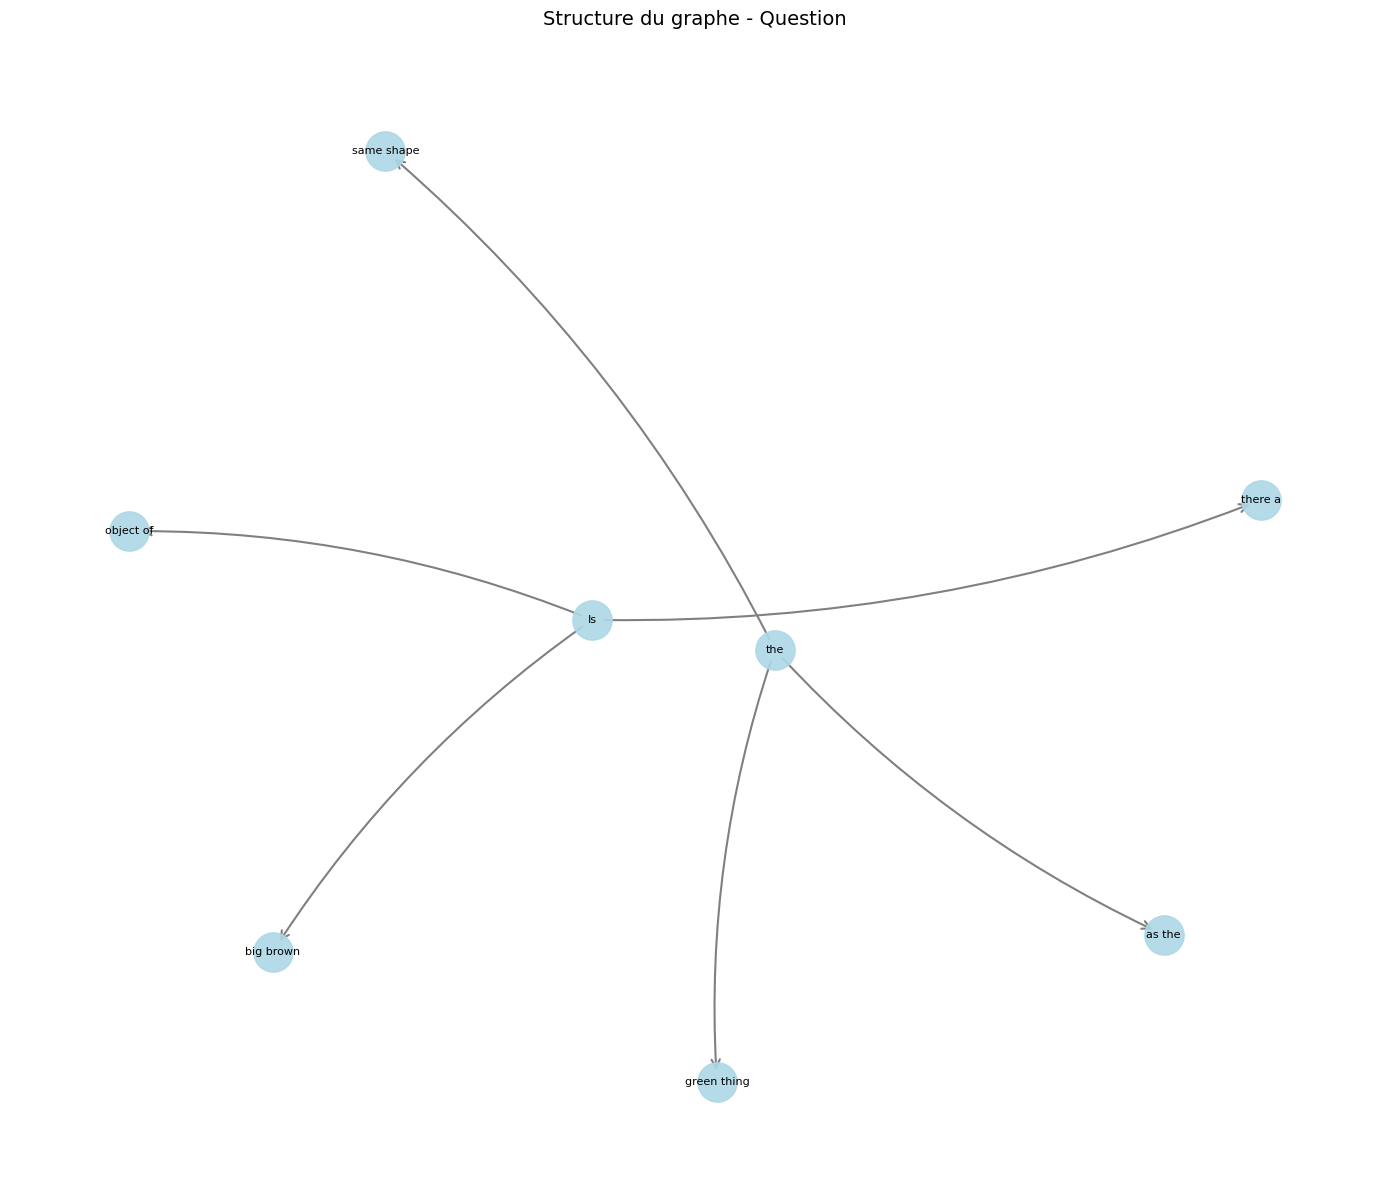

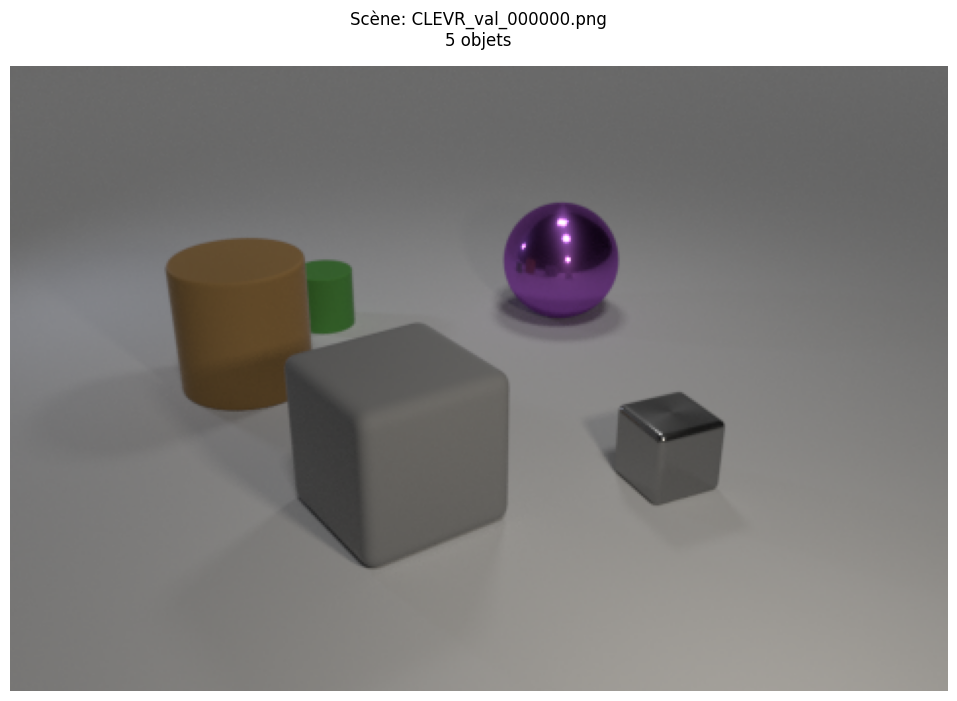

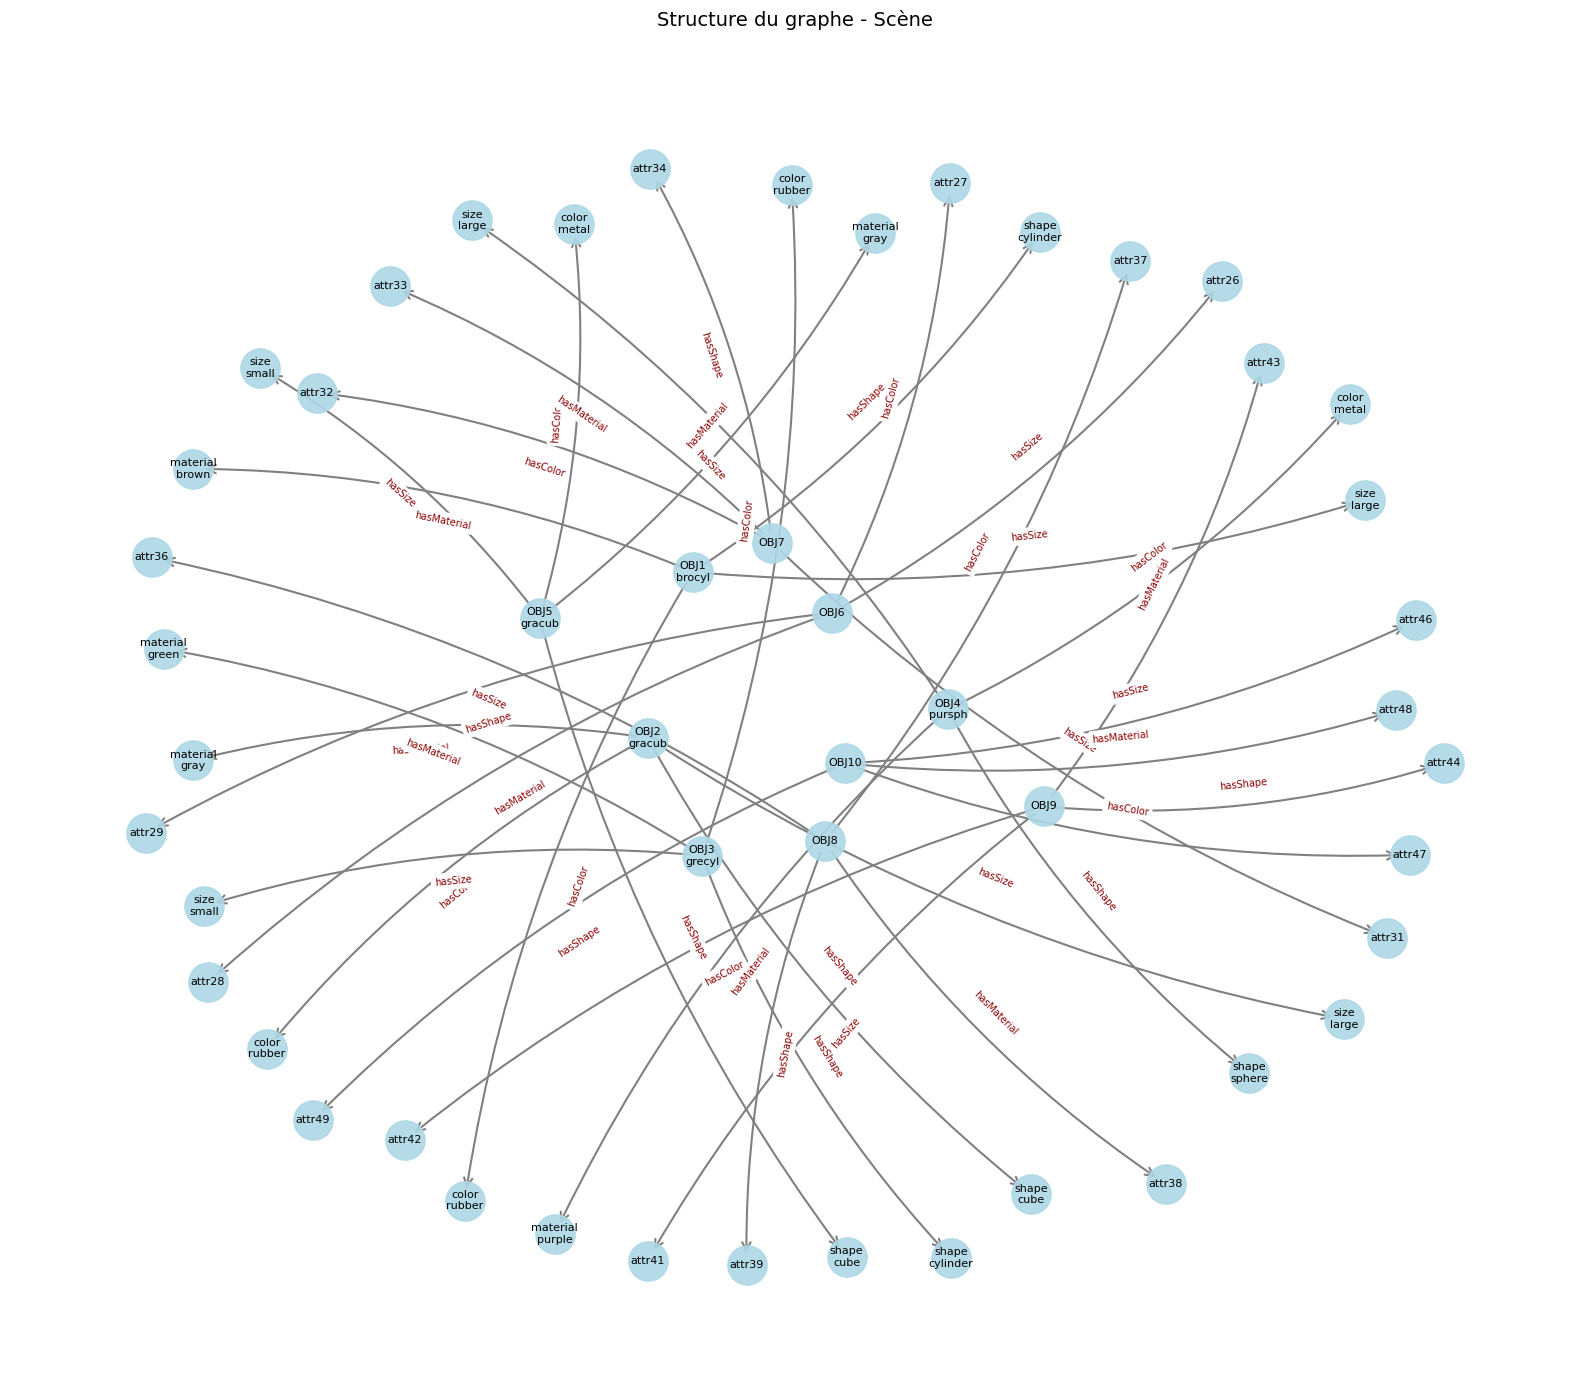

🤖 Prédiction directe: no (confiance: 30.95%) ❌

--------------------------------------------------------------------------------
📌 Exemple 2/3 | idx dataset: 12
❓ Question: How many metallic objects are big blue cubes or blue objects?
✅ Réponse attendue: 2


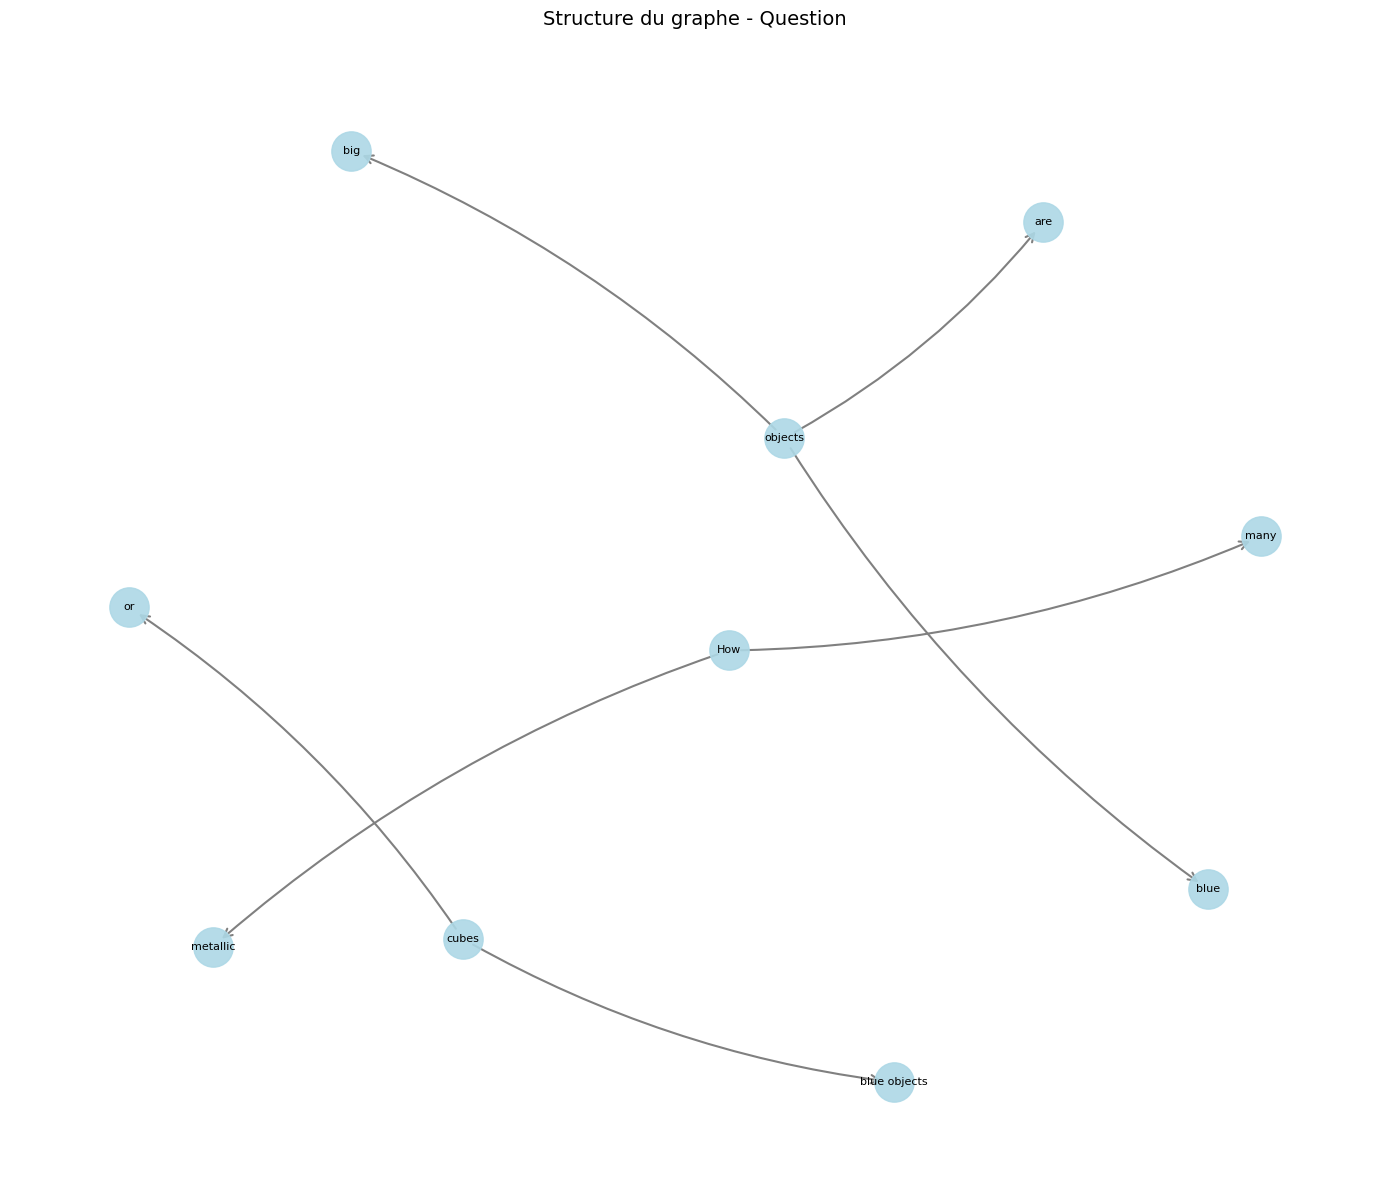

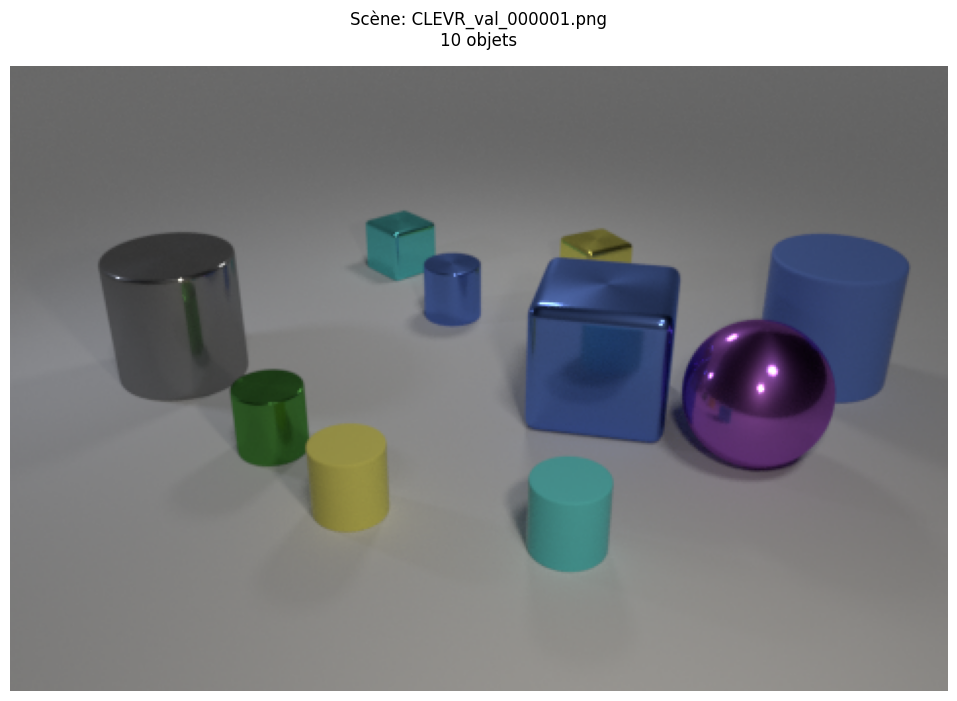

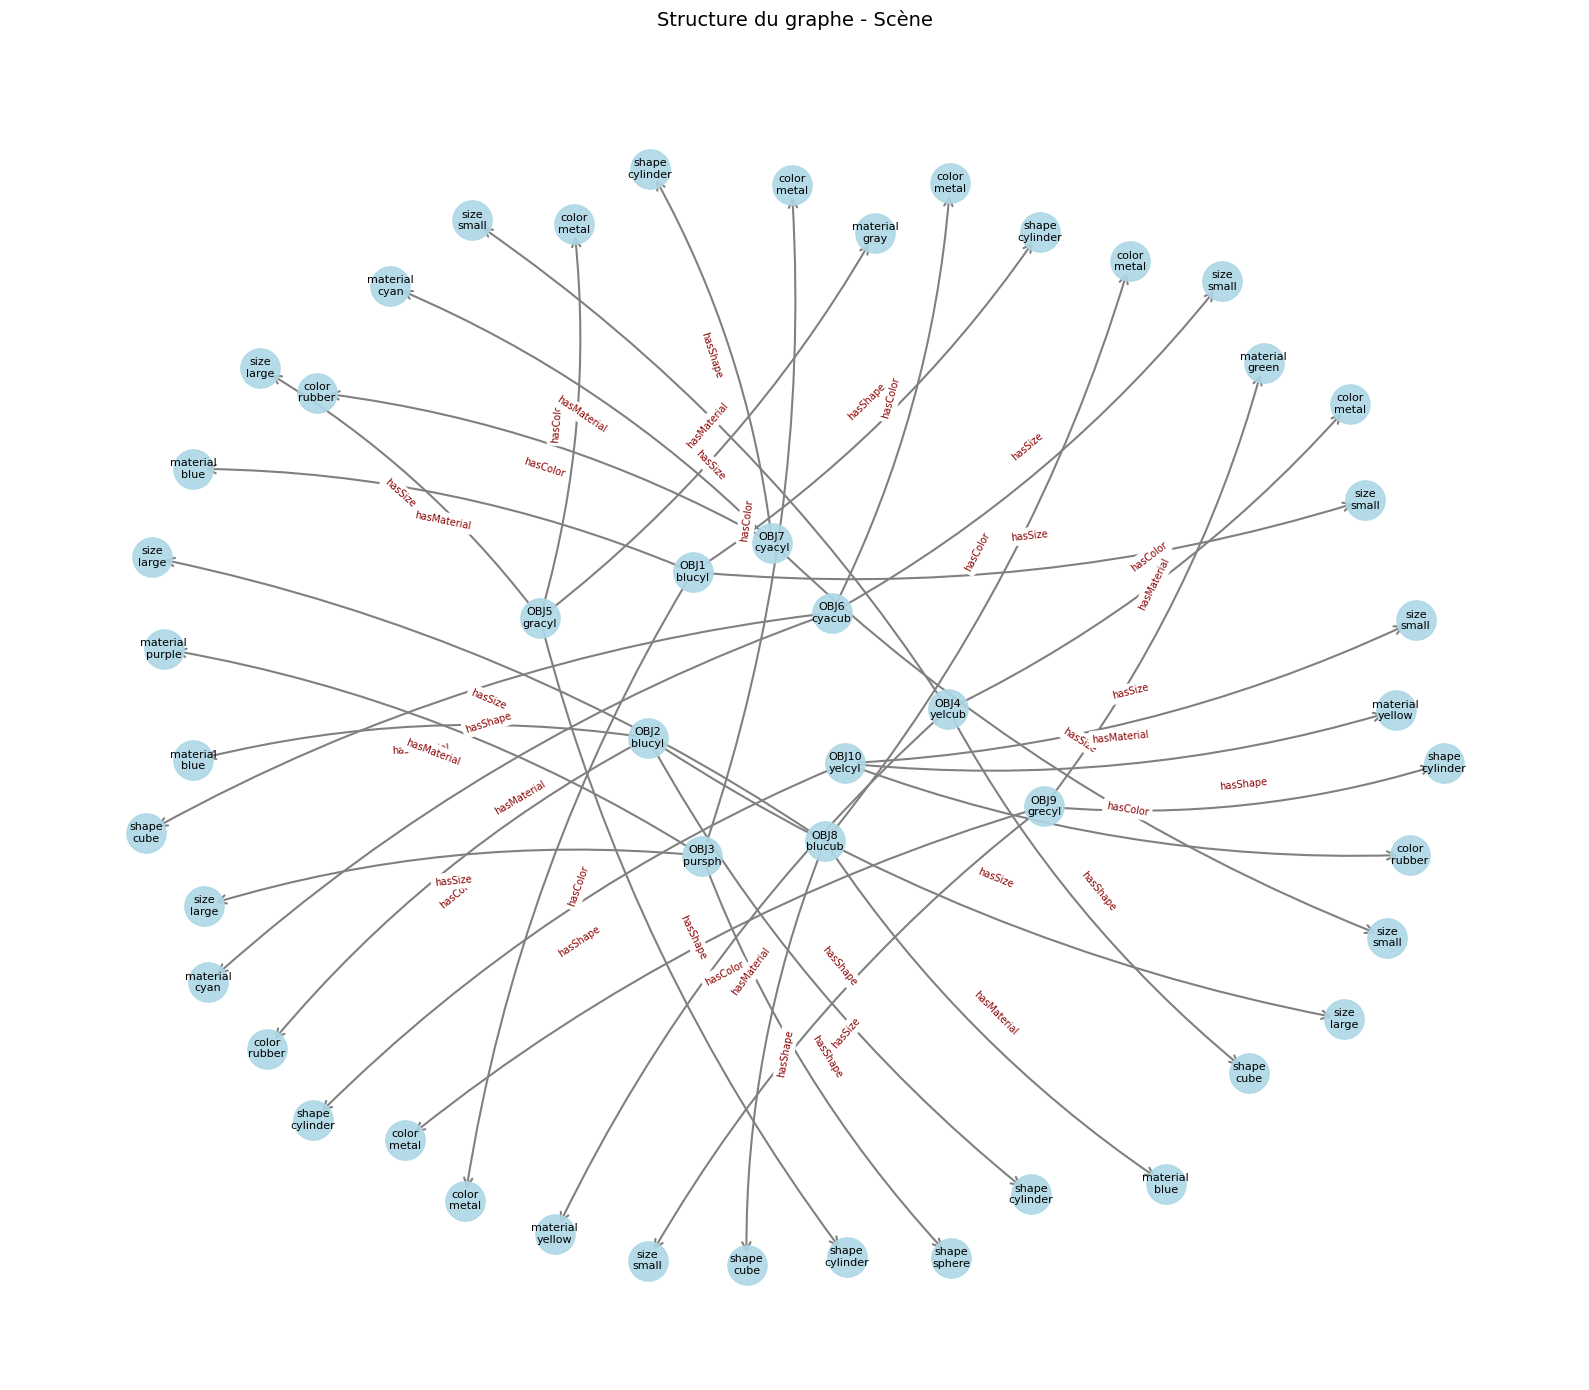

🤖 Prédiction directe: no (confiance: 18.53%) ❌

--------------------------------------------------------------------------------
📌 Exemple 3/3 | idx dataset: 13
❓ Question: Is the color of the big matte object the same as the large metal cube?
✅ Réponse attendue: yes


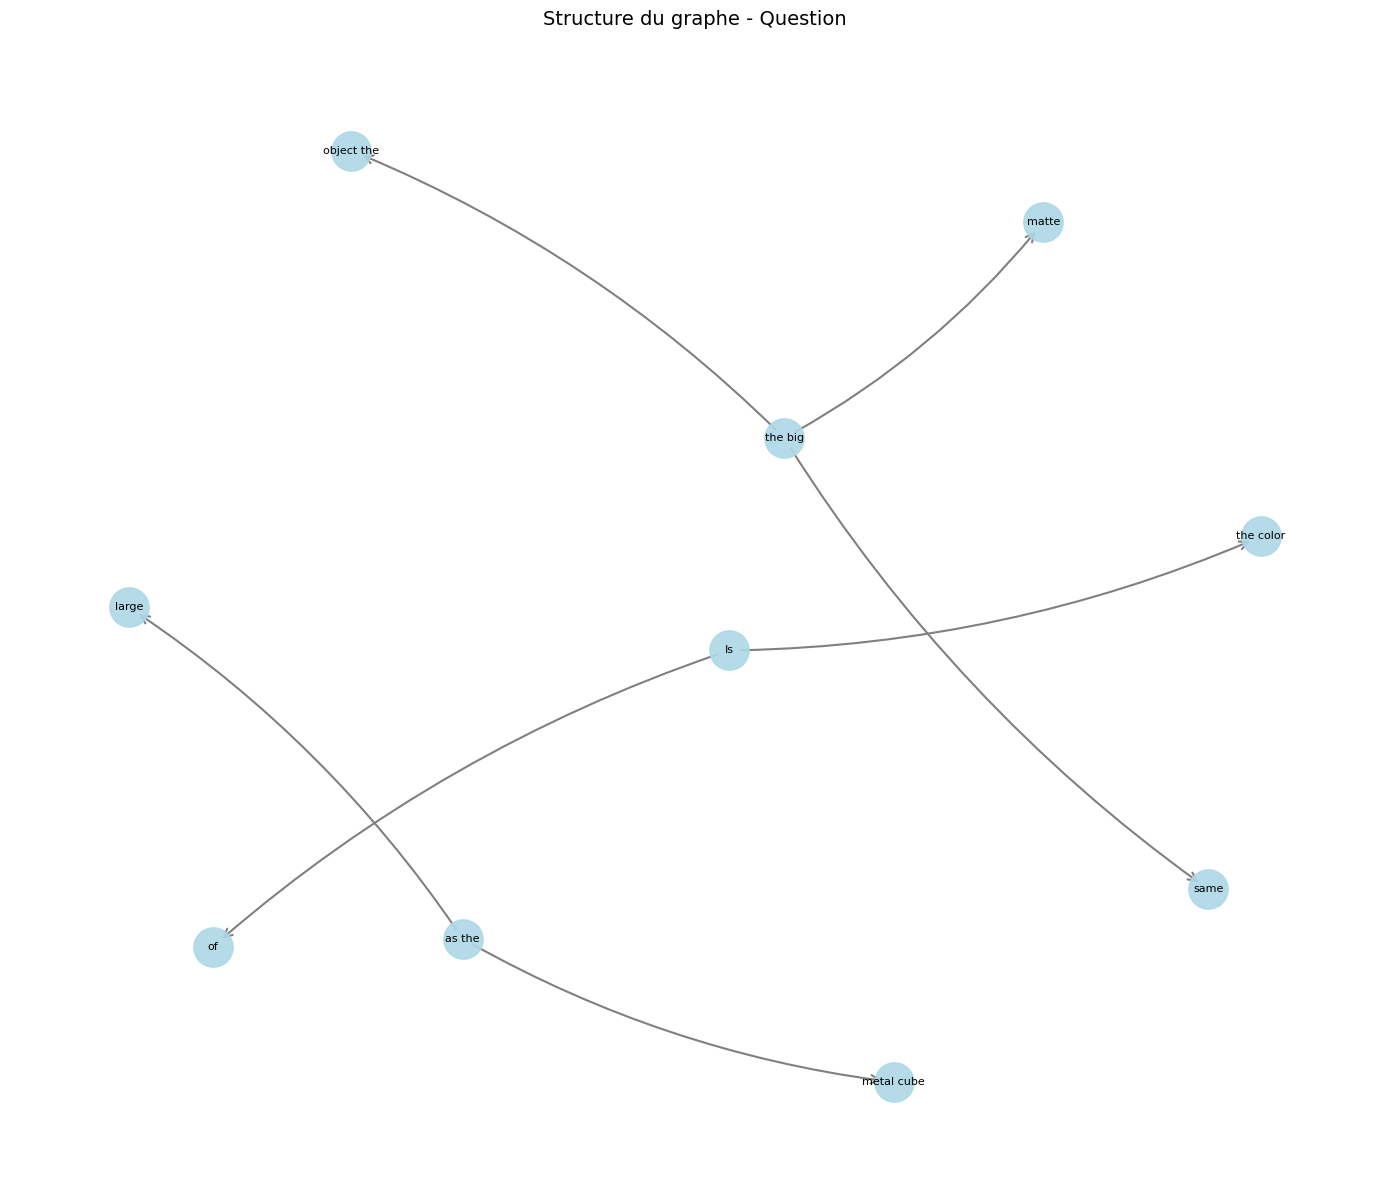

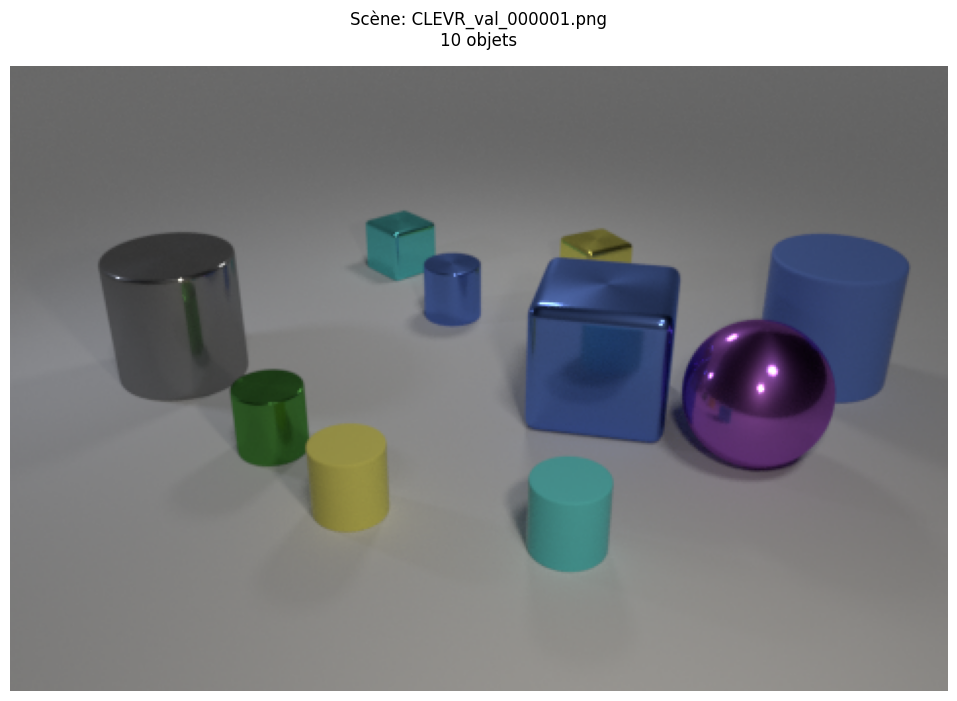

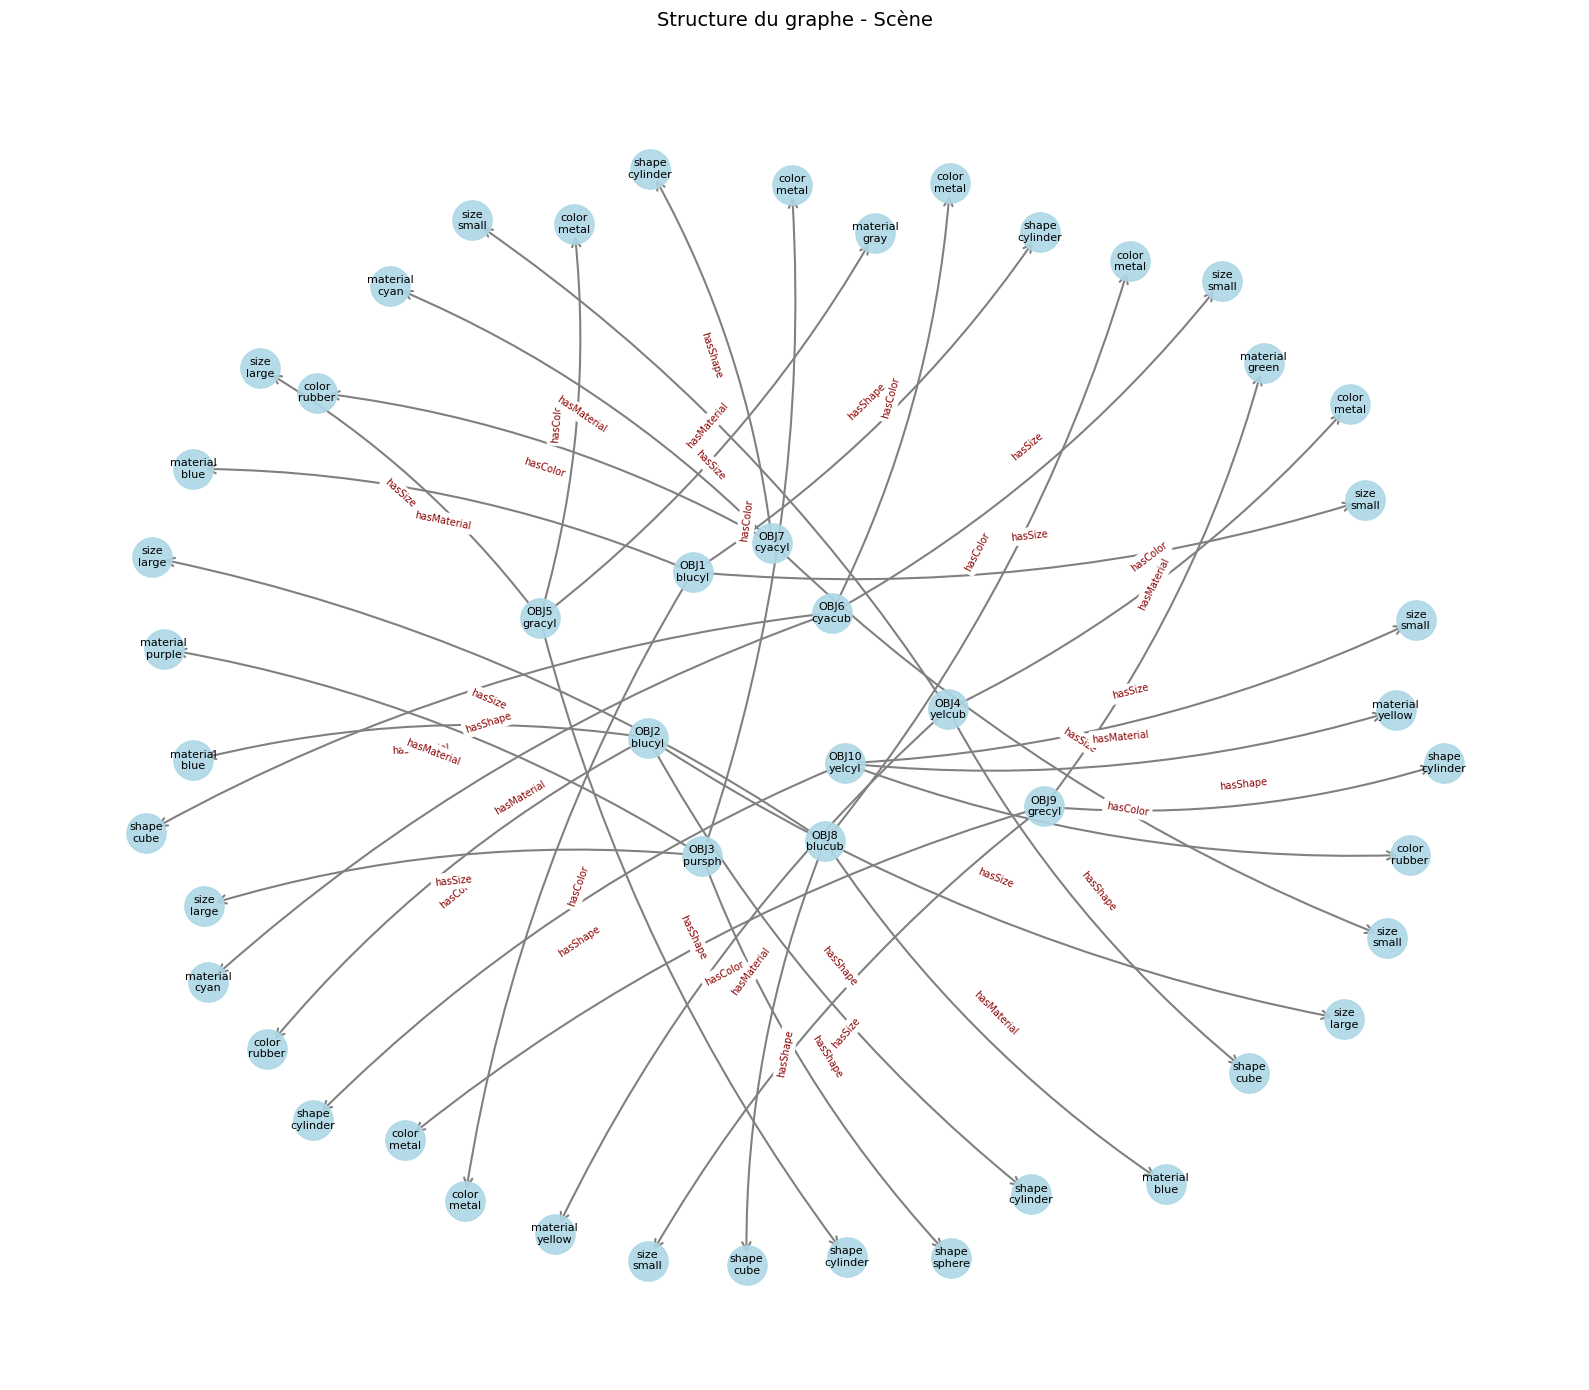

🤖 Prédiction directe: no (confiance: 31.47%) ❌

✅ Visualisation terminée


In [ ]:
# 🎯 Visualisation unifiée (GAT/GIN, two-stream, classification ou seq2seq)
import sys
if 'xai' in sys.modules:
    del sys.modules['xai']
from xai import visualize_programs_and_predictions

visualize_programs_and_predictions(model, val_loader, val_dataset, opt, num_examples=3)